In [1]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import warnings
warnings.filterwarnings("ignore")

In [2]:
GROUP = "C6"
DTYPE="LBP"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C6_10,29,"[DATA/TRAINING/C6/C6_10/IMG_7602.HEIC, DATA/TR..."
1,C6_11,29,"[DATA/TRAINING/C6/C6_11/IMG_7781.HEIC, DATA/TR..."
2,C6_12,27,"[DATA/TRAINING/C6/C6_12/IMG_7852.HEIC, DATA/TR..."
3,C6_13,25,"[DATA/TRAINING/C6/C6_13/IMG_7910.HEIC, DATA/TR..."
4,C6_14,27,"[DATA/TRAINING/C6/C6_14/IMG_7972.HEIC, DATA/TR..."
5,C6_15,25,"[DATA/TRAINING/C6/C6_15/IMG_8039_edited.jpg, D..."
6,C6_16,25,"[DATA/TRAINING/C6/C6_16/IMG_810 .HEIC, DATA/TR..."


In [3]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [4]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [5]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16% IMG_7602.HEIC')

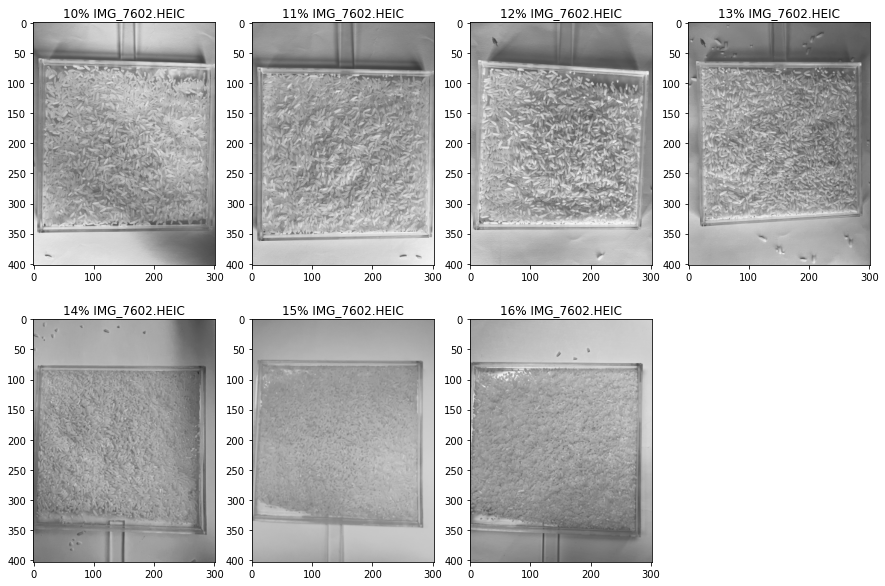

In [14]:
fig=plt.figure(figsize=(15, 10)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][0].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[0][0].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[0][0].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[0][0].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[0][0].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[0][0].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[0][0].split("/")[4])

In [18]:
def fd_gray(gray, bins, mask=None):
    # compute the gray color histogram
    hist  = cv2.calcHist([gray], [0], None, [bins], [0, 256])
    # normalize the histogram
    cv2.normalize(hist, hist)
    # return the histogram
    return hist, hist.flatten()

In [164]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=3
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        # Uniform LBP is used
        P=16; R=2
        lbp_ = local_binary_pattern(gray, P, R, method='uniform')
        n_bins = int(lbp_.max() + 1)
        hist_, bin_edges = np.histogram(lbp_.ravel(), bins=n_bins, range=(0, n_bins), density=True)
        arr_img_hist.append(hist_)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["P"] = P
    pdGrayFeatures["R"] = R
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [165]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(P)+'_'+str(R)+'bins.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,16,17,scale,P,R,height,width,channels,IMAGENAME,HUMIDITY
0,0.075000,0.061852,0.035000,0.021111,0.019259,0.021667,0.025000,0.031389,0.038056,0.032870,...,0.080648,0.398981,3,16,2,120,90,3,IMG_7602.HEIC,10
1,0.076204,0.057130,0.037407,0.022778,0.020093,0.022315,0.023519,0.032593,0.032963,0.035370,...,0.081759,0.392500,3,16,2,120,90,3,IMG_7605.HEIC,10
2,0.080278,0.058981,0.036296,0.022778,0.016759,0.020741,0.022778,0.029537,0.031019,0.032222,...,0.084074,0.404074,3,16,2,120,90,3,IMG_7607.HEIC,10
3,0.076852,0.060278,0.031111,0.023611,0.016111,0.016019,0.019352,0.032130,0.040833,0.038056,...,0.077315,0.412315,3,16,2,120,90,3,IMG_7610.HEIC,10
4,0.081111,0.061204,0.033426,0.022315,0.017870,0.017130,0.019259,0.027870,0.038241,0.037037,...,0.078519,0.412130,3,16,2,120,90,3,IMG_7613.HEIC,10
5,0.078241,0.057037,0.032315,0.024352,0.017407,0.023704,0.024722,0.032130,0.040000,0.039722,...,0.077685,0.395648,3,16,2,120,90,3,IMG_7619.HEIC,10
6,0.077407,0.057963,0.034722,0.022407,0.017963,0.018241,0.020741,0.035741,0.050278,0.045370,...,0.078426,0.388796,3,16,2,120,90,3,IMG_7621.HEIC,10
7,0.075093,0.061389,0.035648,0.020556,0.016204,0.018148,0.020556,0.036389,0.052315,0.054167,...,0.077037,0.382593,3,16,2,120,90,3,IMG_7625.HEIC,10
8,0.072685,0.062222,0.032037,0.022130,0.015556,0.018796,0.020648,0.038426,0.064907,0.039352,...,0.072593,0.382870,3,16,2,120,90,3,IMG_7695.HEIC,10
9,0.073519,0.061852,0.032222,0.024630,0.017870,0.017222,0.021481,0.038148,0.062130,0.039630,...,0.072963,0.378148,3,16,2,120,90,3,IMG_7697.HEIC,10


# Classification

In [166]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-8]
#X

In [167]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [168]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [169]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [170]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [171]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["P"]=P; dtFoldTrain["R"]=R; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(P)+'_'+str(R)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,P,R,height,width,channels
0,1,0.789474,0.809524,0.809524,0.809524,LBP,C6,RF_C,3,16,2,120,90,3
1,2,0.842105,0.892857,0.857143,0.874636,LBP,C6,RF_C,3,16,2,120,90,3
2,3,0.736842,0.785714,0.738095,0.761161,LBP,C6,RF_C,3,16,2,120,90,3
3,4,0.842105,0.869048,0.857143,0.863054,LBP,C6,RF_C,3,16,2,120,90,3
4,5,0.947368,0.952381,0.952381,0.952381,LBP,C6,RF_C,3,16,2,120,90,3
5,6,0.526316,0.704762,0.571429,0.631130,LBP,C6,RF_C,3,16,2,120,90,3
6,7,0.578947,0.630952,0.571429,0.599717,LBP,C6,RF_C,3,16,2,120,90,3
7,8,0.722222,0.835714,0.690476,0.756185,LBP,C6,RF_C,3,16,2,120,90,3
8,9,0.777778,0.821429,0.785714,0.803175,LBP,C6,RF_C,3,16,2,120,90,3
9,10,0.888889,0.916667,0.880952,0.898455,LBP,C6,RF_C,3,16,2,120,90,3


In [172]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,LBP,C6,RF_C,0.765205,0.771429,0.794942,0.821905


### MLP Classifier

In [173]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [174]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [175]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["P"]=P; dtFoldTrain["R"]=R; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(P)+'_'+str(R)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,P,R,height,width,channels
0,1,0.684211,0.785714,0.666667,0.721311,LBP,C6,MLP_C,3,16,2,120,90,3
1,2,0.894737,0.916667,0.904762,0.910675,LBP,C6,MLP_C,3,16,2,120,90,3
2,3,0.736842,0.785714,0.761905,0.773626,LBP,C6,MLP_C,3,16,2,120,90,3
3,4,0.631579,0.616667,0.642857,0.629490,LBP,C6,MLP_C,3,16,2,120,90,3
4,5,0.789474,0.833333,0.809524,0.821256,LBP,C6,MLP_C,3,16,2,120,90,3
5,6,0.631579,0.742857,0.666667,0.702703,LBP,C6,MLP_C,3,16,2,120,90,3
6,7,0.789474,0.809524,0.809524,0.809524,LBP,C6,MLP_C,3,16,2,120,90,3
7,8,0.833333,0.880952,0.857143,0.868885,LBP,C6,MLP_C,3,16,2,120,90,3
8,9,0.722222,0.714286,0.690476,0.702179,LBP,C6,MLP_C,3,16,2,120,90,3
9,10,0.777778,0.809524,0.785714,0.797441,LBP,C6,MLP_C,3,16,2,120,90,3


In [176]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,LBP,C6,MLP_C,0.749123,0.759524,0.773709,0.789524


### XGBoost Classifier

In [177]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [178]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["P"]=P; dtFoldTrain["R"]=R; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(P)+'_'+str(R)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,P,R,height,width,channels
0,1,0.684211,0.776190,0.714286,0.743953,LBP,C6,XGB_C,3,16,2,120,90,3
1,2,0.578947,0.604762,0.571429,0.587623,LBP,C6,XGB_C,3,16,2,120,90,3
2,3,0.526316,0.500000,0.500000,0.500000,LBP,C6,XGB_C,3,16,2,120,90,3
3,4,0.631579,0.628571,0.666667,0.647059,LBP,C6,XGB_C,3,16,2,120,90,3
4,5,0.578947,0.595238,0.595238,0.595238,LBP,C6,XGB_C,3,16,2,120,90,3
5,6,0.684211,0.666667,0.714286,0.689655,LBP,C6,XGB_C,3,16,2,120,90,3
6,7,0.789474,0.821429,0.809524,0.815433,LBP,C6,XGB_C,3,16,2,120,90,3
7,8,0.833333,0.845238,0.833333,0.839243,LBP,C6,XGB_C,3,16,2,120,90,3
8,9,0.666667,0.752381,0.666667,0.706935,LBP,C6,XGB_C,3,16,2,120,90,3
9,10,0.777778,0.809524,0.785714,0.797441,LBP,C6,XGB_C,3,16,2,120,90,3


In [179]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,LBP,C6,XGB_C,0.675146,0.685714,0.692258,0.7


# External validation

In [180]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C6_10,5,"[DATA/TEST/C6/C6_10/IMG_7593.HEIC, DATA/TEST/C..."
1,C6_11,5,"[DATA/TEST/C6/C6_11/IMG_7772.HEIC, DATA/TEST/C..."
2,C6_12,5,"[DATA/TEST/C6/C6_12/IMG_7684.HEIC, DATA/TEST/C..."
3,C6_13,5,"[DATA/TEST/C6/C6_13/IMG_7919.HEIC, DATA/TEST/C..."
4,C6_14,5,"[DATA/TEST/C6/C6_14/IMG_7980.HEIC, DATA/TEST/C..."
5,C6_15,5,"[DATA/TEST/C6/C6_15/IMG_8049_edited.jpg, DATA/..."
6,C6_16,5,"[DATA/TEST/C6/C6_16/IMG_8105.HEIC, DATA/TEST/C..."


In [181]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [182]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        # Uniform LBP is used
        P=16; R=2
        lbp_ = local_binary_pattern(gray, P, R, method='uniform')
        n_bins = int(lbp_.max() + 1)
        hist_, bin_edges = np.histogram(lbp_.ravel(), bins=n_bins, range=(0, n_bins), density=True)
        arr_img_hist.append(hist_)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["P"] = P
    pdGrayFeatures["R"] = R
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [183]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(P)+'_'+str(R)+'bins.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,16,17,scale,P,R,height,width,channels,IMAGENAME,HUMIDITY
0,0.079907,0.055370,0.034074,0.024352,0.019907,0.022037,0.022593,0.029907,0.036852,0.040093,...,0.081852,0.402685,3,16,2,120,90,3,IMG_7593.HEIC,10
1,0.081204,0.061667,0.032130,0.020833,0.016296,0.018148,0.021574,0.026759,0.042222,0.037315,...,0.082500,0.408426,3,16,2,120,90,3,IMG_7594.HEIC,10
2,0.081389,0.064537,0.033333,0.019259,0.016759,0.019815,0.024074,0.032685,0.040463,0.032500,...,0.084630,0.400741,3,16,2,120,90,3,IMG_7597.HEIC,10
3,0.083519,0.059722,0.034537,0.023333,0.018333,0.020185,0.017963,0.026389,0.035370,0.032870,...,0.083241,0.407407,3,16,2,120,90,3,IMG_7599.HEIC,10
4,0.077315,0.053611,0.033241,0.024630,0.016296,0.021759,0.024074,0.032685,0.044352,0.042593,...,0.082870,0.401574,3,16,2,120,90,3,IMG_7601.HEIC,10
0,0.072130,0.056019,0.031204,0.022222,0.015556,0.019352,0.023796,0.036111,0.055278,0.044167,...,0.074444,0.390278,3,16,2,120,90,3,IMG_7772.HEIC,11
1,0.070463,0.055926,0.035093,0.020648,0.015370,0.018611,0.022315,0.034722,0.056852,0.045926,...,0.078519,0.387407,3,16,2,120,90,3,IMG_7773.HEIC,11
2,0.076389,0.057870,0.033704,0.023889,0.014537,0.017222,0.019815,0.027407,0.046944,0.033241,...,0.080463,0.416759,3,16,2,120,90,3,IMG_7774.HEIC,11
3,0.074074,0.056574,0.034630,0.022870,0.015185,0.018426,0.023796,0.033241,0.044630,0.040741,...,0.076389,0.395556,3,16,2,120,90,3,IMG_7777.HEIC,11
4,0.077778,0.058981,0.030741,0.021111,0.015370,0.016944,0.023241,0.034537,0.051944,0.040741,...,0.079352,0.394907,3,16,2,120,90,3,IMG_7778.HEIC,11


In [184]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [185]:
X_test = dtFeaturesTest.values[:, :-8]
#X_test

In [186]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [187]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [188]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.62      1.00      0.77         5
     Class 1       1.00      0.60      0.75         5
     Class 2       0.67      0.80      0.73         5
     Class 3       1.00      0.60      0.75         5
     Class 4       1.00      1.00      1.00         5
     Class 5       1.00      1.00      1.00         5
     Class 6       1.00      1.00      1.00         5

    accuracy                           0.86        35
   macro avg       0.90      0.86      0.86        35
weighted avg       0.90      0.86      0.86        35



## MLP

In [189]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [190]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.56      1.00      0.71         5
     Class 1       1.00      0.40      0.57         5
     Class 2       0.67      0.80      0.73         5
     Class 3       1.00      0.60      0.75         5
     Class 4       0.80      0.80      0.80         5
     Class 5       1.00      1.00      1.00         5
     Class 6       0.80      0.80      0.80         5

    accuracy                           0.77        35
   macro avg       0.83      0.77      0.77        35
weighted avg       0.83      0.77      0.77        35



## XGBC

In [191]:
y_pred = modelXGBC.predict(X_test_scale) 

In [192]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.71      1.00      0.83         5
     Class 1       1.00      0.80      0.89         5
     Class 2       0.60      0.60      0.60         5
     Class 3       0.75      0.60      0.67         5
     Class 4       0.80      0.80      0.80         5
     Class 5       1.00      1.00      1.00         5
     Class 6       0.80      0.80      0.80         5

    accuracy                           0.80        35
   macro avg       0.81      0.80      0.80        35
weighted avg       0.81      0.80      0.80        35

